In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
sns.set_style('whitegrid')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
data = pd.read_csv('C:/Users/hp/Downloads/SpamShield-SMS-Spam-Detector/SpamShield-SMS-Spam-Detector/data/SMSSpamCollection', sep='\t', names=['label', 'text'])
print(data.shape)
data.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# DATA CLEANING


In [8]:
print('Missing values:\n', data.isnull().sum())
print('Duplicates: ', data.duplicated().sum())

data = data.drop_duplicates().reset_index(drop=True)
print('Rows after removing duplicates:', data.shape[0])

data['label_num'] = data['label'].map({'ham': 0, 'spam': 1})
data['label'].value_counts()

Missing values:
 label    0
text     0
dtype: int64
Duplicates:  403
Rows after removing duplicates: 5169


label
ham     4516
spam     653
Name: count, dtype: int64

# TEXT PREPROCESSING


In [9]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' url ', text)   # links
    text = re.sub(r'\d+', ' num ', text)                 # numbers
    text = re.sub(r'[^a-z\s]', ' ', text)                # punctuation / symbols
    tokens = text.split()                                 # tokenization

    clean_tokens = []
    for w in tokens:
        if w not in stop_words and len(w) > 1:           # drop stopwords and single letters
            clean_tokens.append(stemmer.stem(w))         # stem and keep

    return ' '.join(clean_tokens)

data['clean_text'] = data['text'].apply(preprocess)
data[['text', 'clean_text']].head(5)

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri num wkli comp win fa cup final tkt ...
3,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


# EDA / VISUALIZATION

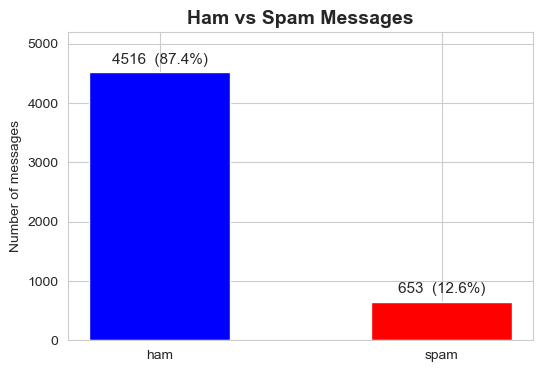

In [10]:
counts = data['label'].value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=['blue', 'red'], width=0.5)

# show count and percentage on top of each bar
labels = [f'{v}  ({v / len(data):.1%})' for v in counts.values]
plt.bar_label(bars, labels=labels, fontsize=11, padding=4)

plt.title('Ham vs Spam Messages', fontsize=14, fontweight='bold')
plt.ylabel('Number of messages')
plt.ylim(0, counts.max() * 1.15)   # leave room for the labels
plt.show()

label
ham      70.905890
spam    137.704441
Name: length, dtype: float64


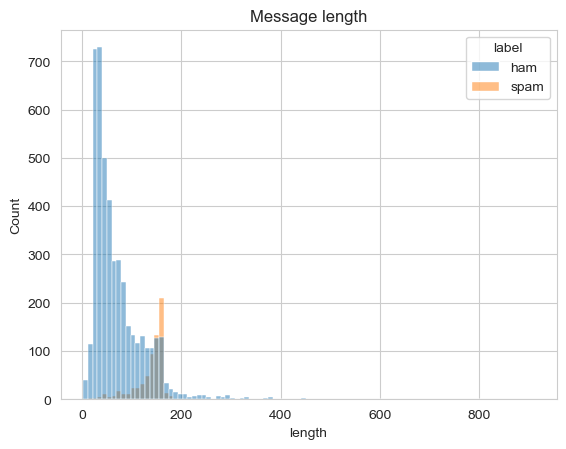

In [11]:
data['length'] = data['text'].apply(len)

print(data.groupby('label')['length'].mean())

sns.histplot(data=data, x='length', hue='label')
plt.title('Message length')
plt.show()

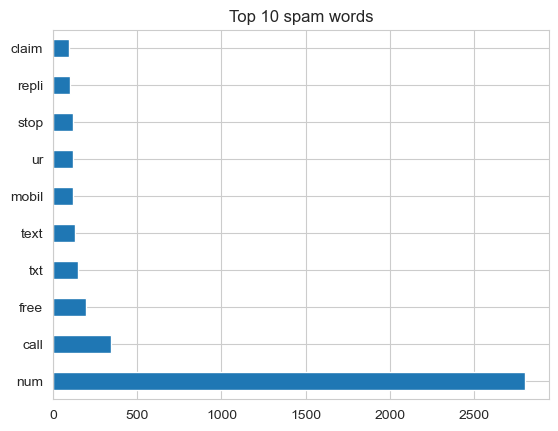

In [12]:
spam_words = ' '.join(data[data['label'] == 'spam']['clean_text']).split()

pd.Series(spam_words).value_counts().head(10).plot(kind='barh')
plt.title('Top 10 spam words')
plt.show()

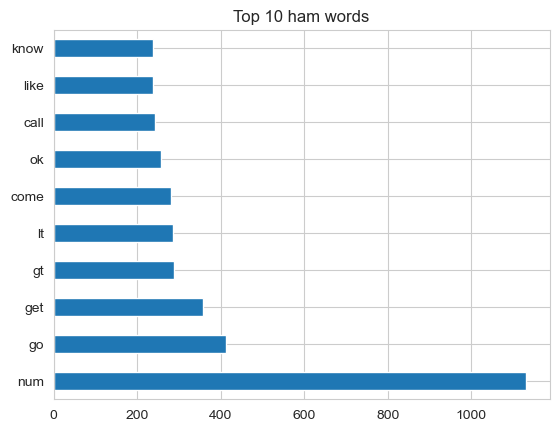

In [13]:
ham_words = ' '.join(data[data['label'] == 'ham']['clean_text']).split()

pd.Series(ham_words).value_counts().head(10).plot(kind='barh')
plt.title('Top 10 ham words')
plt.show()

In [14]:
data[['label', 'label_num', 'text', 'clean_text']].to_csv('cleaned_data.csv', index=False)